<a href="https://colab.research.google.com/github/benammarn/BMU-Datenanalyse/blob/main/GenAI_Vehicle_Scene_Analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

print("Hallo! Mein GenAI-Projekt startet.")

a = 10
b = 20

print("Ergebnis:", a + b)


Hallo! Mein GenAI-Projekt startet.
Ergebnis: 30


In [1]:

import torch

print("GPU verfügbar:", torch.cuda.is_available())


GPU verfügbar: True


In [ ]:

!pip install -q -U transformers accelerate pillow requests


In [4]:

!pip install -q "requests==2.32.4" "pillow>=8,<13"


In [5]:

!pip uninstall -y gradio
!pip install -q "requests==2.32.4" "pillow>=13.0.0"


Found existing installation: gradio 6.30.0
Uninstalling gradio-6.30.0:
  Successfully uninstalled gradio-6.30.0


In [7]:

!pip install -q "requests==2.32.4" "pillow>=13.0.0"


In [1]:

import requests
import PIL
import transformers
import torch

print("Requests:", requests.__version__)
print("Pillow:", PIL.__version__)
print("Transformers:", transformers.__version__)
print("GPU verfügbar:", torch.cuda.is_available())

print("Umgebung bereit!")


Requests: 2.32.4
Pillow: 13.0.0
Transformers: 5.21.0
GPU verfügbar: True
Umgebung bereit!


In [2]:

from transformers import pipeline

vlm = pipeline(
    "image-text-to-text",
    model="HuggingFaceTB/SmolVLM-256M-Instruct",
    device=0
)

print("Modell erfolgreich geladen!")


config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  513MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

...

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.74k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.55M [00:00<?, ?B/s]

Modell erfolgreich geladen!


In [3]:

bild_url = (
    "https://huggingface.co/datasets/"
    "huggingface/documentation-images/"
    "resolve/main/p-blog/candy.JPG"
)

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "url": bild_url},
            {
                "type": "text",
                "text": "What animal is visible in this image?"
            }
        ]
    }
]

antwort = vlm(
    text=messages,
    max_new_tokens=60,
    return_full_text=False
)

print("KI-Antwort:")
print(antwort[0]["generated_text"])


KI-Antwort:
 There is no animal visible in the image.


Saving original_89ab691a-681c-9841-fa8f-2ae0b34633f4.jpg to original_89ab691a-681c-9841-fa8f-2ae0b34633f4.jpg
Bild erfolgreich geladen: original_89ab691a-681c-9841-fa8f-2ae0b34633f4.jpg


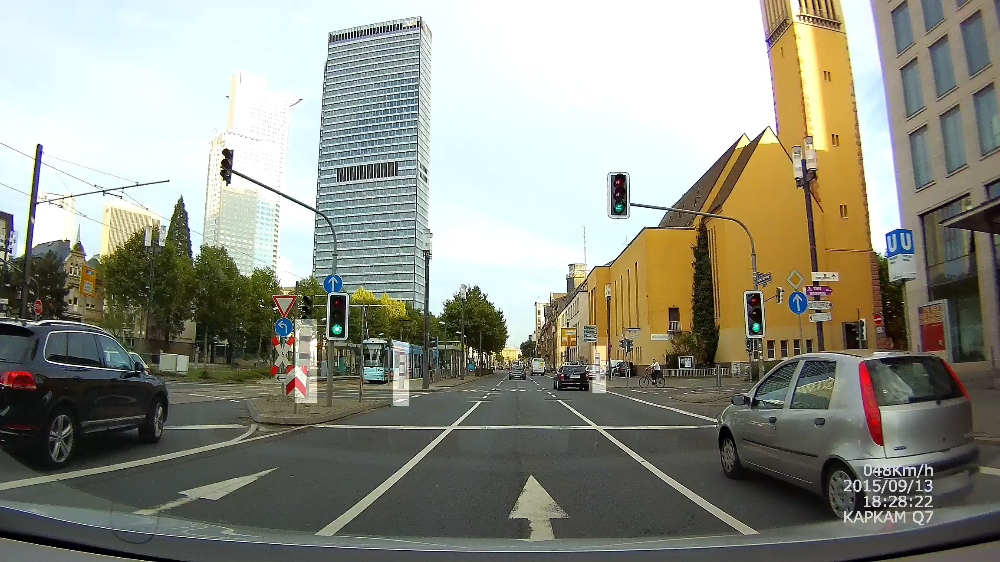

In [4]:

from google.colab import files
from PIL import Image
from io import BytesIO

uploaded = files.upload()

filename = next(iter(uploaded))
bild = Image.open(
    BytesIO(uploaded[filename])
).convert("RGB")

print("Bild erfolgreich geladen:", filename)
display(bild)


In [8]:

# GenAI Vehicle Scene Analyzer
# Analyse eines Verkehrsfotos

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": bild
            },
            {
                "type": "text",
                "text": (
                    "Analyze this traffic scene. "
                    "Describe the visible vehicles, "
                    "pedestrians, cyclists, traffic lights "
                    "and road signs. "
                    "Write 4 to 6 short sentences. "
                    "Only mention clearly visible objects. "
                    "Do not invent anything."
                )
            }
        ]
    }
]

antwort = vlm(
    text=messages,
    max_new_tokens=200,
    return_full_text=False
)

print("=== FAHRZEUGSZENEN-ANALYSE ===")
print(antwort[0]["generated_text"])


=== FAHRZEUGSZENEN-ANALYSE ===
 4 to 6 sentences.


In [9]:

import torch
from transformers import AutoProcessor

# Bild und Modell sind bereits geladen
processor = AutoProcessor.from_pretrained(
    "HuggingFaceTB/SmolVLM-256M-Instruct"
)

# Einfache Frage an das Modell
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": bild},
            {
                "type": "text",
                "text": "Describe what you see in this image."
            }
        ]
    }
]

# Bild und Frage für das Modell vorbereiten
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt"
).to(vlm.model.device)

# Neue Antwort erzeugen
with torch.no_grad():
    outputs = vlm.model.generate(
        **inputs,
        max_new_tokens=150,
        do_sample=False
    )

# Nur die neue Antwort auslesen
input_length = inputs["input_ids"].shape[1]

antwort = processor.decode(
    outputs[0][input_length:],
    skip_special_tokens=True
)

print("=== FAHRZEUGSZENEN-ANALYSE ===")
print(antwort)


=== FAHRZEUGSZENEN-ANALYSE ===
 The image depicts a street scene in what appears to be a city. The street is lined with tall buildings, which are likely residential or office buildings, given their architectural style and the presence of windows. The buildings are multi-storied, with a variety of architectural styles, including modern and older styles.

On the left side of the image, there is a street sign with a red cross symbol and the text "STOP" in white letters. This sign is located on the left side of the image, indicating that vehicles must stop at this intersection.

On the right side of the image, there is a street sign with the text "TRIOTT" in blue letters. This sign is located on the right side of


In [10]:
import torch
from transformers import AutoProcessor

processor = AutoProcessor.from_pretrained(
    "HuggingFaceTB/SmolVLM-256M-Instruct"
)

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": bild},
            {
                "type": "text",
                "text": (
                    "Analyze this traffic image and answer in the following format:\n"
                    "Cars: ...\n"
                    "Pedestrians: ...\n"
                    "Cyclists: ...\n"
                    "Traffic lights: ...\n"
                    "Road signs: ...\n"
                    "Summary: ...\n\n"
                    "Only mention clearly visible objects. "
                    "If something is not clearly visible, write 'not clearly visible'."
                )
            }
        ]
    }
]

inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt"
).to(vlm.model.device)

with torch.no_grad():
    outputs = vlm.model.generate(
        **inputs,
        max_new_tokens=200,
        do_sample=False
    )

input_length = inputs["input_ids"].shape[1]

antwort = processor.decode(
    outputs[0][input_length:],
    skip_special_tokens=True
)

print("=== STRUKTURIERTE VERKEHRSANALYSE ===")
print(antwort)

=== STRUKTURIERTE VERKEHRSANALYSE ===
 Skyscrapers


In [11]:

import gc
import torch
from transformers import (
    AutoProcessor,
    AutoModelForImageTextToText
)

# Altes Modell aus dem Arbeitsspeicher entfernen
del vlm
gc.collect()
torch.cuda.empty_cache()

# Neues Modell auswählen
model_name = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"

processor = AutoProcessor.from_pretrained(model_name)

model = AutoModelForImageTextToText.from_pretrained(
    model_name,
    dtype=torch.float16,
    device_map="auto"
)

model.eval()

print("Neues VLM erfolgreich geladen!")


processor_config.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/430 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.6k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.55M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.74k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/868 [00:00<?, ?B/s]

ImportError: Package `num2words` is required to run SmolVLM processor. Install it with `pip install num2words`.

In [12]:

!pip install -q num2words


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [13]:

import torch
from transformers import (
    AutoProcessor,
    AutoModelForImageTextToText
)

model_name = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"

# Bildverarbeitung vorbereiten
processor = AutoProcessor.from_pretrained(model_name)

# KI-Modell auf die GPU laden
model = AutoModelForImageTextToText.from_pretrained(
    model_name,
    dtype=torch.float16,
    device_map="auto"
)

model.eval()

print("SmolVLM2 erfolgreich geladen!")
print("Modell:", model_name)
print("Gerät:", model.device)


ImportError: Package `num2words` is required to run SmolVLM processor. Install it with `pip install num2words`.

In [1]:

%pip install -q num2words

import num2words
print("num2words erfolgreich installiert!")


num2words erfolgreich installiert!


In [2]:

import torch
import num2words
from transformers import (
    AutoProcessor,
    AutoModelForImageTextToText
)

model_name = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"

processor = AutoProcessor.from_pretrained(model_name)

model = AutoModelForImageTextToText.from_pretrained(
    model_name,
    dtype=torch.float16,
    device_map="auto"
)

model.eval()

print("SmolVLM2 erfolgreich geladen!")
print("Gerät:", model.device)


model.safetensors.index.json:   0%|          | 0.00/63.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

SmolVLM2 erfolgreich geladen!
Gerät: cuda:0


Saving original_89ab691a-681c-9841-fa8f-2ae0b34633f4.jpg to original_89ab691a-681c-9841-fa8f-2ae0b34633f4 (1).jpg
Bild erfolgreich geladen: original_89ab691a-681c-9841-fa8f-2ae0b34633f4 (1).jpg


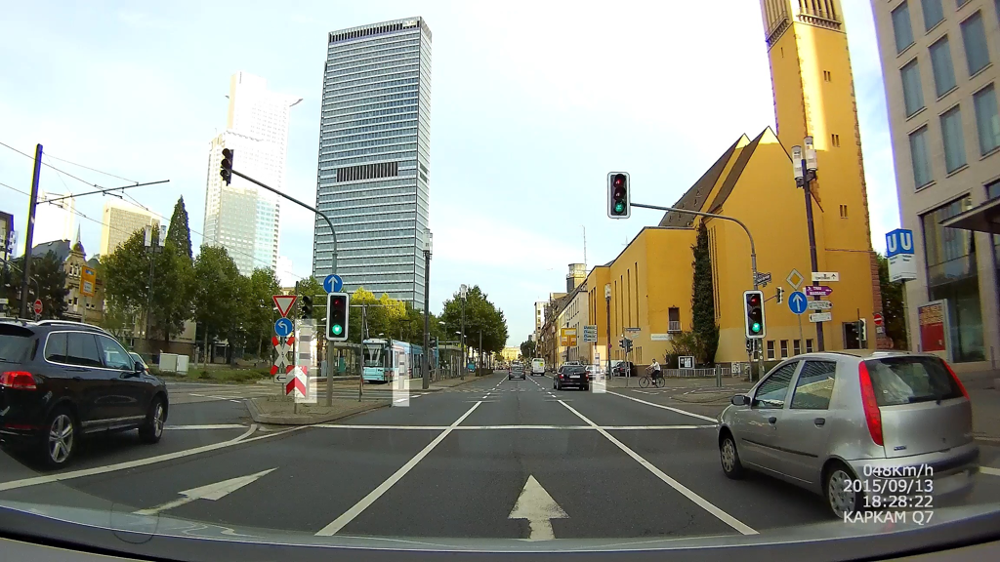

In [3]:

from google.colab import files
from PIL import Image
from io import BytesIO

uploaded = files.upload()

filename = next(iter(uploaded))
bild = Image.open(
    BytesIO(uploaded[filename])
).convert("RGB")

# Bildgröße für die Analyse begrenzen
bild.thumbnail((1024, 1024))

print("Bild erfolgreich geladen:", filename)
display(bild)


In [4]:

import torch

# Anfrage an das Vision-Language-Modell
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": bild},
            {
                "type": "text",
                "text": (
                    "Describe the visible vehicles, "
                    "traffic lights, pedestrians and road signs "
                    "in this street image. "
                    "Use 2 or 3 sentences. "
                    "Do not guess text on signs."
                )
            }
        ]
    }
]

# Bild und Text vorbereiten
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt"
).to(model.device, dtype=torch.float16)

# KI-Modell ausführen
with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=180,
        do_sample=False
    )

# Antwort ohne ursprüngliche Eingabe auslesen
input_length = inputs["input_ids"].shape[-1]

analyse = processor.decode(
    outputs[0][input_length:],
    skip_special_tokens=True
)

print("=== GENAI VEHICLE SCENE ANALYZER ===")
print(analyse)


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


=== GENAI VEHICLE SCENE ANALYZER ===
 There are two cars, a silver car and a black car, a traffic light, a pedestrian crossing sign, and a road sign with an arrow.


In [5]:

import json
from google.colab import files

# Ergebnis unseres KI-Modells
ergebnis = {
    "projekt": "GenAI Vehicle Scene Analyzer",
    "modell": "SmolVLM2-2.2B-Instruct",
    "bild": filename,
    "bildbeschreibung": analyse.strip(),
    "manuell_geprueft": False
}

# Ergebnis als JSON speichern
with open("verkehrsanalyse_01.json", "w", encoding="utf-8") as datei:
    json.dump(ergebnis, datei, indent=4, ensure_ascii=False)

# Ergebnis anzeigen
print(json.dumps(ergebnis, indent=4, ensure_ascii=False))

# Datei herunterladen
files.download("verkehrsanalyse_01.json")


{
    "projekt": "GenAI Vehicle Scene Analyzer",
    "modell": "SmolVLM2-2.2B-Instruct",
    "bild": "original_89ab691a-681c-9841-fa8f-2ae0b34633f4 (1).jpg",
    "bildbeschreibung": "There are two cars, a silver car and a black car, a traffic light, a pedestrian crossing sign, and a road sign with an arrow.",
    "manuell_geprueft": false
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

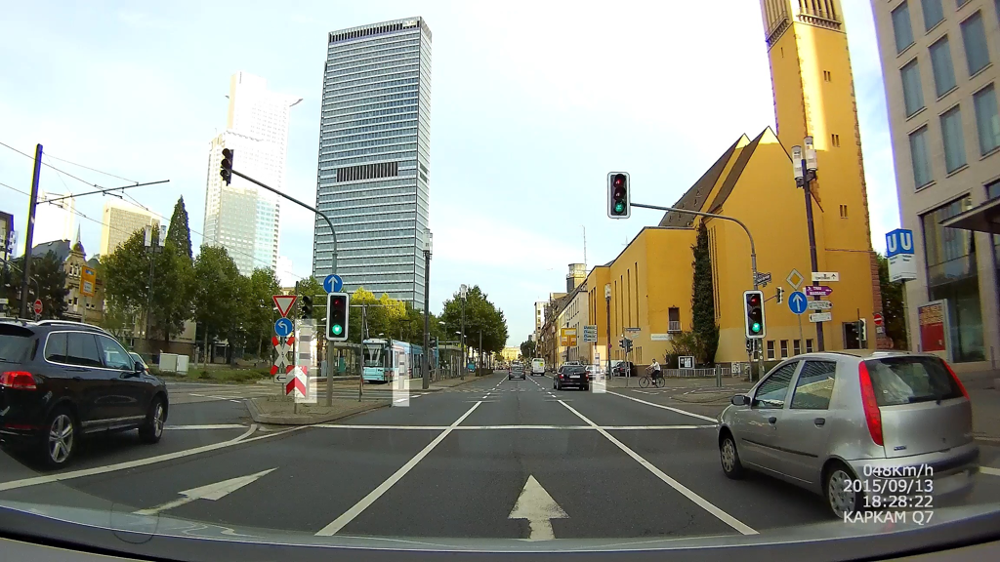

KI-Analyse:
 There are two cars, a silver car and a black car, a traffic light, a pedestrian crossing sign, and a road sign with an arrow.


KeyboardInterrupt: Interrupted by user

In [6]:

import json
from google.colab import files

# Verkehrsbild noch einmal anzeigen
display(bild)

print("KI-Analyse:")
print(analyse)

# Aussagen des Modells überprüfen
aussagen = {
    "zwei_autos": "Sind genau zwei Autos sichtbar?",
    "autofarben": "Ist ein Auto silber und eines schwarz?",
    "ampel": "Ist eine Ampel sichtbar?",
    "fussgaengerschild": "Ist ein Fußgängerüberweg-Schild sichtbar?",
    "pfeilschild": "Ist ein Verkehrsschild mit Pfeil sichtbar?"
}

bewertungen = {}

for schluessel, frage in aussagen.items():
    while True:
        antwort = input(
            frage + " (j=ja, n=nein, u=unsicher): "
        ).strip().lower()

        if antwort in ("j", "n", "u"):
            break

        print("Bitte j, n oder u eingeben.")

    bewertungen[schluessel] = {
        "aussage": frage,
        "bewertung": {
            "j": "richtig",
            "n": "falsch",
            "u": "unsicher"
        }[antwort]
    }

# Ergebnisse zusammenfassen
auswertung = {
    "modell": "SmolVLM2-2.2B-Instruct",
    "bild": filename,
    "ki_beschreibung": analyse.strip(),
    "manuell_geprueft": True,
    "bewertungen": bewertungen
}

# JSON-Datei speichern
with open(
    "verkehrsanalyse_01_geprueft.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        auswertung, f,
        indent=4,
        ensure_ascii=False
    )

print("\n=== MANUELLE AUSWERTUNG ===")
for punkt in bewertungen.values():
    print(punkt["aussage"], punkt["bewertung"])

files.download("verkehrsanalyse_01_geprueft.json")


In [11]:

import json
from google.colab import files

# Deine Antworten:
# j = richtig, n = falsch, u = unsicher
antworten = ["j", "n", "j", "u", "n"]

fragen = [
    "Genau zwei Autos sichtbar",
    "Ein silbernes und ein schwarzes Auto",
    "Eine Ampel sichtbar",
    "Fussgaengerueberweg-Schild sichtbar",
    "Verkehrsschild mit Pfeil sichtbar"
]

bewertungstexte = {
    "j": "richtig",
    "n": "falsch",
    "u": "unsicher"
}

bewertungen = {}

for frage, antwort in zip(fragen, antworten):
    bewertungen[frage] = bewertungstexte[antwort]

ergebnis = {
    "projekt": "GenAI Vehicle Scene Analyzer",
    "modell": "SmolVLM2-2.2B-Instruct",
    "bild": filename,
    "ki_analyse": analyse.strip(),
    "manuelle_bewertung": bewertungen
}

# JSON-Datei erstellen
with open("verkehrsanalyse_geprueft.json", "w", encoding="utf-8") as f:
    json.dump(ergebnis, f, indent=4, ensure_ascii=False)

print("=== ERGEBNIS DER AUSWERTUNG ===")
for frage, bewertung in bewertungen.items():
    print(frage, ":", bewertung)

print("\nJSON-Datei erfolgreich erstellt!")

files.download("verkehrsanalyse_geprueft.json")


=== ERGEBNIS DER AUSWERTUNG ===
Genau zwei Autos sichtbar : richtig
Ein silbernes und ein schwarzes Auto : falsch
Eine Ampel sichtbar : richtig
Fussgaengerueberweg-Schild sichtbar : unsicher
Verkehrsschild mit Pfeil sichtbar : falsch

JSON-Datei erfolgreich erstellt!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

import json

# Gespeicherte Bewertung einlesen
with open("verkehrsanalyse_geprueft.json", "r", encoding="utf-8") as f:
    daten = json.load(f)

bewertungen = list(daten["manuelle_bewertung"].values())

# Bewertungen automatisch zählen
richtig = bewertungen.count("richtig")
falsch = bewertungen.count("falsch")
unsicher = bewertungen.count("unsicher")

# Nur eindeutig bewertete Aussagen berücksichtigen
gesamt = richtig + falsch

if gesamt > 0:
    trefferquote = richtig / gesamt * 100
else:
    trefferquote = None

print("=== VLM EVALUATION REPORT ===")
print("Modell:", daten["modell"])
print("Richtige Aussagen:", richtig)
print("Falsche Aussagen:", falsch)
print("Unsichere Aussagen:", unsicher)

if trefferquote is not None:
    print(f"Trefferquote: {trefferquote:.1f}%")
else:
    print("Keine eindeutigen Bewertungen vorhanden")


=== VLM EVALUATION REPORT ===
Modell: SmolVLM2-2.2B-Instruct
Richtige Aussagen: 2
Falsche Aussagen: 2
Unsichere Aussagen: 1
Trefferquote: 50.0%


In [13]:

import torch
import json
from PIL import Image
from io import BytesIO
from google.colab import files

print("Bitte mehrere Verkehrsbilder auswählen.")

uploaded = files.upload()

ergebnisse = []

for dateiname, dateiinhalt in uploaded.items():

    print("\nAnalysiere:", dateiname)

    # Verkehrsbild laden
    bild_test = Image.open(
        BytesIO(dateiinhalt)
    ).convert("RGB")

    bild_test.thumbnail((1024, 1024))

    # KI-Anfrage
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": bild_test},
                {
                    "type": "text",
                    "text": (
                        "Describe the visible vehicles, "
                        "pedestrians, cyclists, traffic lights "
                        "and road signs in this image. "
                        "Use 2 to 4 sentences. "
                        "Only describe clearly visible objects."
                    )
                }
            ]
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(model.device, dtype=torch.float16)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False
        )

    input_length = inputs["input_ids"].shape[-1]

    beschreibung = processor.decode(
        outputs[0][input_length:],
        skip_special_tokens=True
    ).strip()

    print("KI-Ergebnis:", beschreibung)

    ergebnisse.append({
        "bild": dateiname,
        "modell": "SmolVLM2-2.2B-Instruct",
        "beschreibung": beschreibung,
        "manuell_geprueft": False
    })

# Alle Analysen in einer JSON-Datei speichern
with open(
    "mehrbild_analysen.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        ergebnisse,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\n=== ANALYSE ABGESCHLOSSEN ===")
print("Analysierte Bilder:", len(ergebnisse))

files.download("mehrbild_analysen.json")


Bitte mehrere Verkehrsbilder auswählen.


Saving Cars_at_a_traffic_light.jpg to Cars_at_a_traffic_light.jpg
Saving Pedestrians_crossing_the_street_in_downtown_Washington_DC.jpg to Pedestrians_crossing_the_street_in_downtown_Washington_DC.jpg
Saving Traffic_jam_at_MM_ALAM_Road.jpg to Traffic_jam_at_MM_ALAM_Road.jpg

Analysiere: Cars_at_a_traffic_light.jpg


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


KI-Ergebnis: There are several cars on the road, a traffic light, and a few road signs.

Analysiere: Pedestrians_crossing_the_street_in_downtown_Washington_DC.jpg


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


KI-Ergebnis: There are several cars on the road, including a black SUV, a white van, and a few other vehicles. Pedestrians are walking on the sidewalk, and there are traffic lights and road signs visible at the intersection.

Analysiere: Traffic_jam_at_MM_ALAM_Road.jpg
KI-Ergebnis: There are cars, buses, and pedestrians on the road. There are traffic lights and road signs.

=== ANALYSE ABGESCHLOSSEN ===
Analysierte Bilder: 3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

=== GENAI VEHICLE SCENE ANALYZER ===
Visuelle Überprüfung der 3 Bilder

BILD 1
Datei: Cars_at_a_traffic_light.jpg


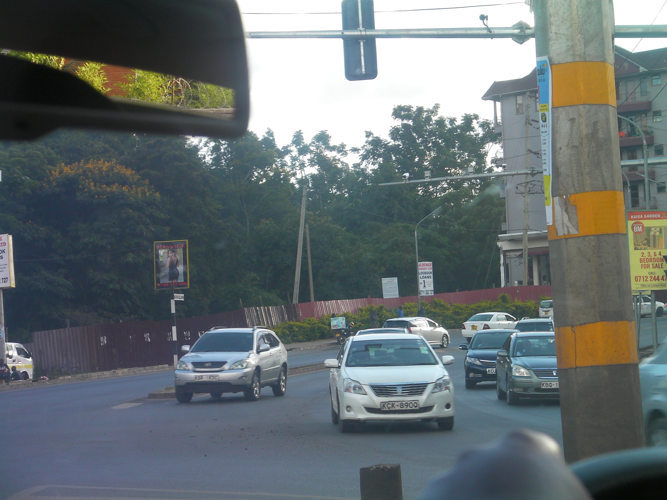

KI-BESCHREIBUNG:
There are several cars on the road, a traffic light, and a few road signs.

Bitte visuell überprüfen.

BILD 2
Datei: Pedestrians_crossing_the_street_in_downtown_Washington_DC.jpg


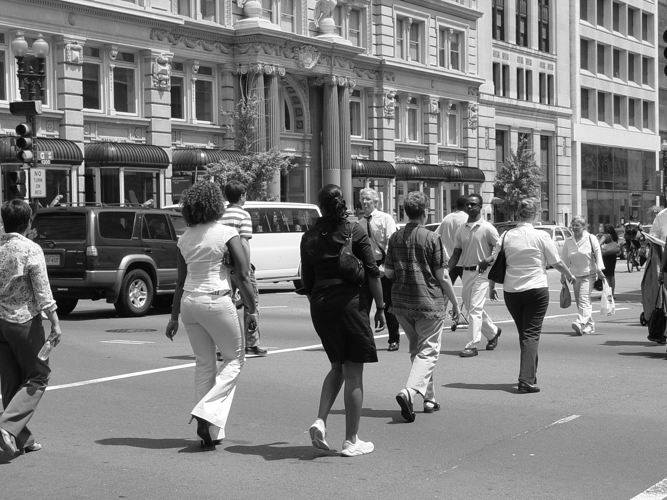

KI-BESCHREIBUNG:
There are several cars on the road, including a black SUV, a white van, and a few other vehicles. Pedestrians are walking on the sidewalk, and there are traffic lights and road signs visible at the intersection.

Bitte visuell überprüfen.

BILD 3
Datei: Traffic_jam_at_MM_ALAM_Road.jpg


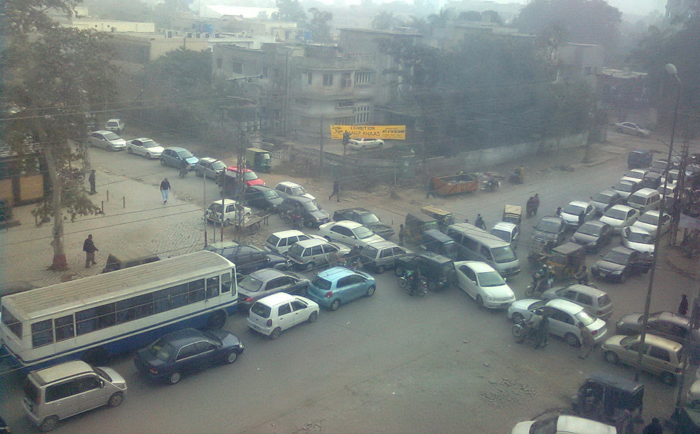

KI-BESCHREIBUNG:
There are cars, buses, and pedestrians on the road. There are traffic lights and road signs.

Bitte visuell überprüfen.


In [14]:

from PIL import Image
from io import BytesIO
from IPython.display import display

print("=== GENAI VEHICLE SCENE ANALYZER ===")
print("Visuelle Überprüfung der 3 Bilder")

for nummer, eintrag in enumerate(ergebnisse, start=1):

    dateiname = eintrag["bild"]

    print("\n" + "=" * 50)
    print("BILD", nummer)
    print("Datei:", dateiname)

    # Originalbild anzeigen
    if dateiname in uploaded:
        foto = Image.open(
            BytesIO(uploaded[dateiname])
        ).convert("RGB")

        foto.thumbnail((700, 500))
        display(foto)

    # KI-Beschreibung anzeigen
    print("KI-BESCHREIBUNG:")
    print(eintrag["beschreibung"])

    print("\nBitte visuell überprüfen.")



BILD 1


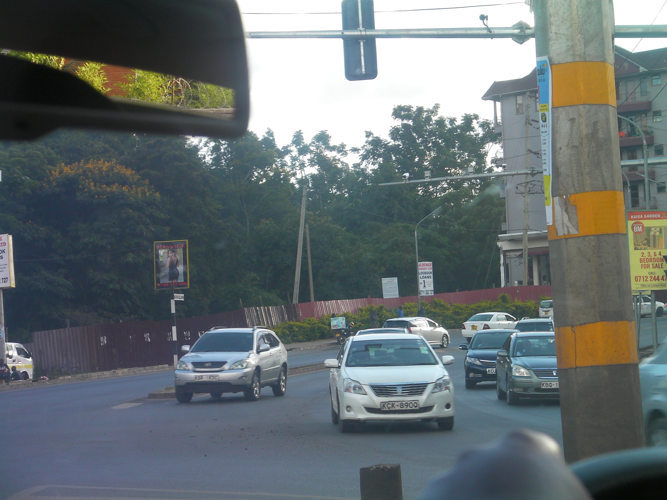

KI-ANALYSE:
There are several cars on the road, a traffic light, and a few road signs.

BILD 2


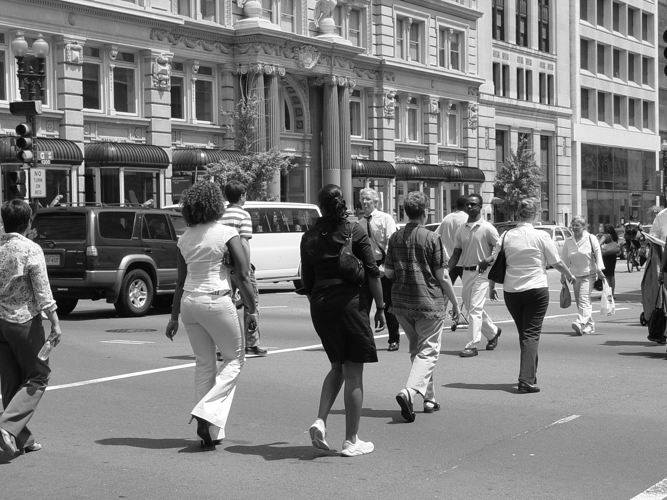

KI-ANALYSE:
There are several cars on the road, including a black SUV, a white van, and a few other vehicles. Pedestrians are walking on the sidewalk, and there are traffic lights and road signs visible at the intersection.

BILD 3


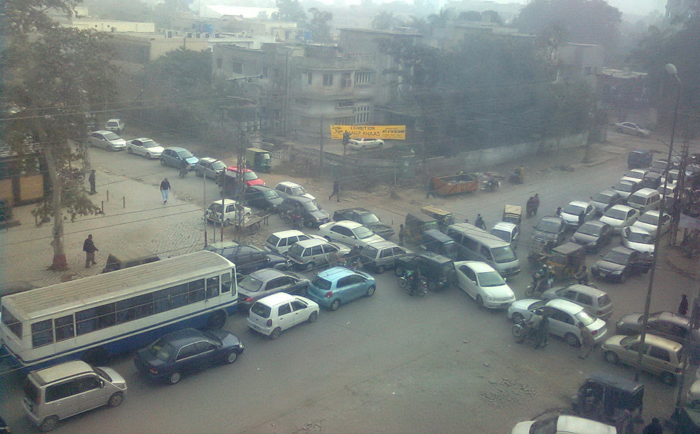

KI-ANALYSE:
There are cars, buses, and pedestrians on the road. There are traffic lights and road signs.


In [15]:

import os
from PIL import Image
from IPython.display import display
from google.colab import files

# Prüfen, ob alle Bilder noch vorhanden sind
fehlende = [
    e["bild"] for e in ergebnisse
    if not os.path.isfile(e["bild"])
]

if fehlende:
    print("Bitte diese Bilder erneut hochladen:")
    print(fehlende)
    files.upload()

# Bilder und KI-Analysen anzeigen
for nummer, eintrag in enumerate(ergebnisse, start=1):
    dateiname = eintrag["bild"]

    print("\n" + "=" * 50)
    print("BILD", nummer)

    if os.path.isfile(dateiname):
        foto = Image.open(dateiname).convert("RGB")
        foto.thumbnail((700, 500))
        display(foto)
    else:
        print("Bilddatei nicht gefunden:", dateiname)

    print("KI-ANALYSE:")
    print(eintrag["beschreibung"])


In [16]:

import json
import os
from google.colab import files

# Bisherige KI-Ergebnisse verwenden
if "ergebnisse" not in globals():
    if not os.path.exists("mehrbild_analysen.json"):
        print("Bitte mehrbild_analysen.json hochladen:")
        files.upload()

    with open("mehrbild_analysen.json", "r", encoding="utf-8") as f:
        ergebnisse = json.load(f)

# Deine tatsächlichen manuellen Bewertungen
bewertungen = {
    "Cars_at_a_traffic_light.jpg": "richtig",
    "Pedestrians_crossing_the_street_in_downtown_Washington_DC.jpg": "richtig",
    "Traffic_jam_at_MM_ALAM_Road.jpg": "teilweise richtig"
}

# Zusätzliche Anmerkungen
anmerkungen = {
    "Cars_at_a_traffic_light.jpg": "",
    "Pedestrians_crossing_the_street_in_downtown_Washington_DC.jpg": "",
    "Traffic_jam_at_MM_ALAM_Road.jpg":
        "Konkrete Abweichung noch nicht dokumentiert"
}

# Bewertungen mit den KI-Analysen verbinden
gepruefte_ergebnisse = []

for eintrag in ergebnisse:
    dateiname = eintrag["bild"]

    if dateiname not in bewertungen:
        raise ValueError(f"Keine Bewertung für {dateiname}")

    gepruefte_ergebnisse.append({
        "bild": dateiname,
        "modell": eintrag["modell"],
        "ki_beschreibung": eintrag["beschreibung"],
        "manuelle_bewertung": bewertungen[dateiname],
        "anmerkung": anmerkungen[dateiname],
        "manuell_geprueft": True
    })

# Statistik berechnen
gesamt = len(gepruefte_ergebnisse)

richtig = sum(
    e["manuelle_bewertung"] == "richtig"
    for e in gepruefte_ergebnisse
)

teilweise = sum(
    e["manuelle_bewertung"] == "teilweise richtig"
    for e in gepruefte_ergebnisse
)

falsch = sum(
    e["manuelle_bewertung"] == "falsch"
    for e in gepruefte_ergebnisse
)

quote = (richtig / gesamt * 100) if gesamt else 0

# Gesamten Bericht erstellen
bericht = {
    "projekt": "GenAI Vehicle Scene Analyzer",
    "modell": "SmolVLM2-2.2B-Instruct",
    "zusammenfassung": {
        "bilder_gesamt": gesamt,
        "richtig": richtig,
        "teilweise_richtig": teilweise,
        "falsch": falsch,
        "vollstaendig_richtig_prozent": round(quote, 2)
    },
    "einzelergebnisse": gepruefte_ergebnisse
}

# Als JSON speichern
dateiname = "evaluation_3_bilder.json"

with open(dateiname, "w", encoding="utf-8") as f:
    json.dump(bericht, f, indent=4, ensure_ascii=False)

print("=== GENAI VEHICLE SCENE ANALYZER ===")
print("EVALUATION REPORT")
print("-" * 40)

print("Modell:", bericht["modell"])
print("Analysierte Bilder:", gesamt)
print("Richtig:", richtig)
print("Teilweise richtig:", teilweise)
print("Falsch:", falsch)
print(f"Vollständig richtig: {quote:.1f}%")

print("\nEvaluation erfolgreich gespeichert!")

files.download(dateiname)


=== GENAI VEHICLE SCENE ANALYZER ===
EVALUATION REPORT
----------------------------------------
Modell: SmolVLM2-2.2B-Instruct
Analysierte Bilder: 3
Richtig: 2
Teilweise richtig: 1
Falsch: 0
Vollständig richtig: 66.7%

Evaluation erfolgreich gespeichert!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

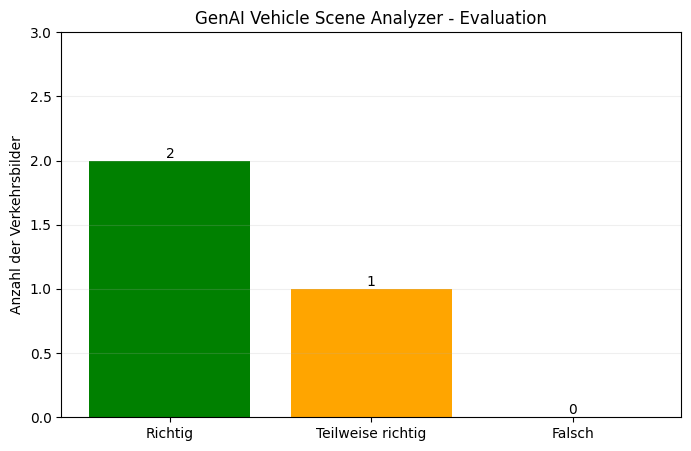

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Diagramm erfolgreich erstellt!


In [17]:

import json
import matplotlib.pyplot as plt
from google.colab import files

# Evaluationsbericht öffnen
with open("evaluation_3_bilder.json", "r", encoding="utf-8") as f:
    bericht = json.load(f)

daten = bericht["zusammenfassung"]

kategorien = ["Richtig", "Teilweise richtig", "Falsch"]
werte = [
    daten["richtig"],
    daten["teilweise_richtig"],
    daten["falsch"]
]

# Diagramm erstellen
plt.figure(figsize=(8, 5))
balken = plt.bar(
    kategorien,
    werte,
    color=["green", "orange", "red"]
)

plt.bar_label(balken)
plt.title("GenAI Vehicle Scene Analyzer - Evaluation")
plt.ylabel("Anzahl der Verkehrsbilder")
plt.ylim(0, 3)
plt.grid(axis="y", alpha=0.2)

plt.savefig("evaluation_diagramm.png", dpi=200)
plt.show()

files.download("evaluation_diagramm.png")

print("Diagramm erfolgreich erstellt!")


In [1]:

%pip install -q ultralytics

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


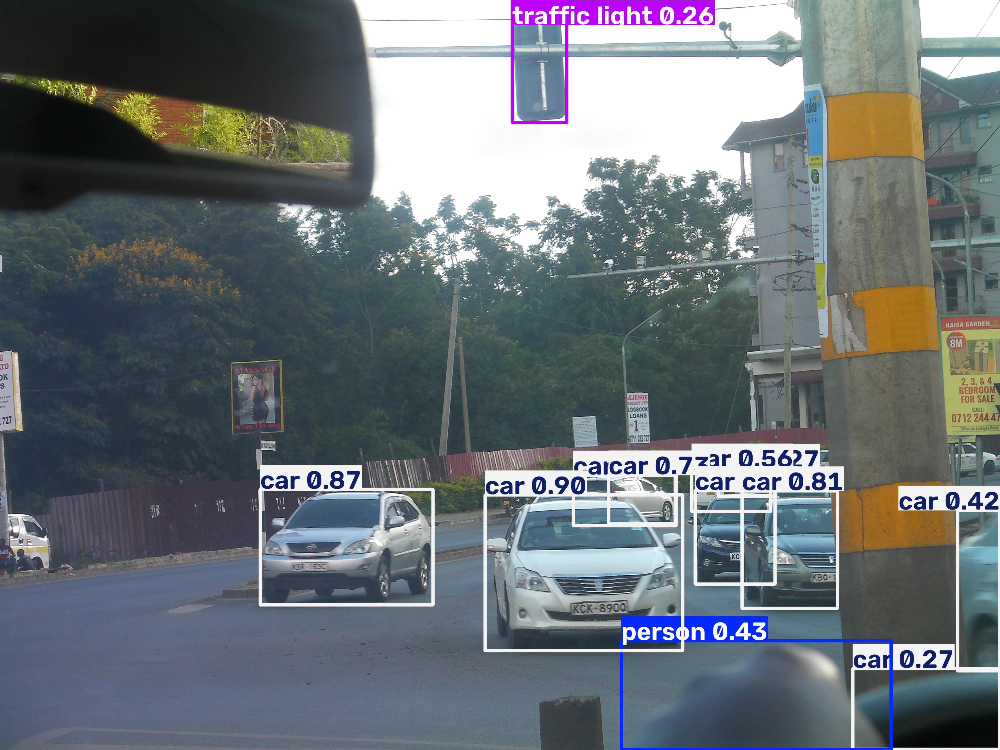

=== YOLO OBJEKTERKENNUNG ===
car: 10
person: 1
traffic light: 1

Bild gespeichert: verkehr_yolo_erkennung.jpg


In [2]:

from ultralytics import YOLO
from PIL import Image
from IPython.display import display
from collections import Counter
import os

# Unser erstes Testbild
bildname = "Cars_at_a_traffic_light.jpg"

# Falls das Bild nicht mehr vorhanden ist
if not os.path.isfile(bildname):
    from google.colab import files
    print("Bitte Cars_at_a_traffic_light.jpg hochladen")
    files.upload()

# Vortrainiertes YOLO11-Modell laden
detektor = YOLO("yolo11n.pt")

# Objekte erkennen
# CPU verwenden, damit SmolVLM2 weiter auf der GPU bleiben kann
resultat = detektor.predict(
    source=bildname,
    conf=0.25,
    device="cpu",
    verbose=False
)[0]

# Bild mit markierten Objekten anzeigen
markiertes_bild = Image.fromarray(
    resultat.plot()[..., ::-1]
)

display(markiertes_bild)

# Ergebnisbild speichern
resultat.save(filename="verkehr_yolo_erkennung.jpg")

# Erkannte Objekte zählen
objekte = [
    resultat.names[int(klasse)]
    for klasse in resultat.boxes.cls.tolist()
]

anzahlen = Counter(objekte)

print("=== YOLO OBJEKTERKENNUNG ===")

for objekt, anzahl in anzahlen.items():
    print(f"{objekt}: {anzahl}")

print("\nBild gespeichert: verkehr_yolo_erkennung.jpg")


In [3]:

import json
import torch
from PIL import Image
from google.colab import files
from collections import Counter

# Dasselbe Bild wie bei YOLO verwenden
foto = Image.open(bildname).convert("RGB")
foto.thumbnail((1024, 1024))

# 1. YOLO-Ergebnisse auslesen
erkennungen = []

for box in resultat.boxes:
    klasse = int(box.cls[0].item())
    objekt = resultat.names[klasse]
    konfidenz = float(box.conf[0].item())

    erkennungen.append({
        "objekt": objekt,
        "konfidenz": round(konfidenz, 3),
        "bbox": [
            round(v, 1)
            for v in box.xyxy[0].tolist()
        ]
    })

anzahlen = dict(Counter(
    e["objekt"] for e in erkennungen
))

# 2. SmolVLM2 analysiert dasselbe Bild
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": foto},
            {
                "type": "text",
                "text": (
                    "Describe the visible vehicles, "
                    "pedestrians, traffic lights and road signs. "
                    "Use 2 or 3 short sentences. "
                    "Do not invent objects."
                )
            }
        ]
    }
]

inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt"
).to(model.device, dtype=torch.float16)

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=180,
        do_sample=False
    )

input_length = inputs["input_ids"].shape[-1]

vlm_antwort = processor.decode(
    outputs[0][input_length:],
    skip_special_tokens=True
).strip()

# 3. Gemeinsamen Bericht erstellen
bericht = {
    "projekt": "GenAI Vehicle Scene Analyzer",
    "bild": bildname,
    "modelle": {
        "objekterkennung": "YOLO11n",
        "bildbeschreibung": "SmolVLM2-2.2B-Instruct"
    },
    "yolo_objektanzahl": anzahlen,
    "yolo_erkennungen": erkennungen,
    "smolvlm_beschreibung": vlm_antwort,
    "manuell_geprueft": False
}

# 4. Bericht speichern
with open("ki_fusion_analyse.json", "w", encoding="utf-8") as f:
    json.dump(bericht, f, indent=4, ensure_ascii=False)

print("=== GENAI VEHICLE SCENE ANALYZER 2.0 ===")

print("\nYOLO-Objekterkennung:")
for objekt, anzahl in anzahlen.items():
    print(objekt, ":", anzahl)

print("\nSmolVLM2-Beschreibung:")
print(vlm_antwort)

print("\nGemeinsamer JSON-Bericht erstellt!")

files.download("ki_fusion_analyse.json")


NameError: name 'processor' is not defined

In [4]:

import torch
from transformers import (
    AutoProcessor,
    AutoModelForImageTextToText
)

model_name = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"

# Bildverarbeitung laden
processor = AutoProcessor.from_pretrained(model_name)

# KI-Modell nur laden, wenn es nicht bereits vorhanden ist
if "model" not in globals():
    print("SmolVLM2 wird geladen ...")

    model = AutoModelForImageTextToText.from_pretrained(
        model_name,
        dtype=torch.float16,
        device_map="auto"
    )

model.eval()

print("=== MODELL BEREIT ===")
print("Processor: OK")
print("SmolVLM2: OK")
print("Gerät:", model.device)


SmolVLM2 wird geladen ...


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

=== MODELL BEREIT ===
Processor: OK
SmolVLM2: OK
Gerät: cuda:0


In [6]:

import torch
import json
from PIL import Image
from collections import Counter
from google.colab import files

# 1. Verkehrsbild laden
foto = Image.open(bildname).convert("RGB")
foto.thumbnail((1024, 1024))

# 2. YOLO-Ergebnisse auslesen
erkennungen = []

for box in resultat.boxes:
    klasse = int(box.cls[0].item())
    objekt = resultat.names[klasse]
    konfidenz = float(box.conf[0].item())

    erkennungen.append({
        "objekt": objekt,
        "konfidenz": round(konfidenz, 3),
        "bbox": box.xyxy[0].tolist()
    })

anzahlen = dict(Counter(
    e["objekt"] for e in erkennungen
))

# 3. Anfrage an SmolVLM2 erstellen
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": foto
            },
            {
                "type": "text",
                "text": (
                    "Describe the vehicles, pedestrians, "
                    "traffic lights and road signs visible "
                    "in this image. "
                    "Use 2 or 3 short sentences. "
                    "Only describe what is clearly visible."
                )
            }
        ]
    }
]

# 4. Bild und Text vorbereiten
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt"
).to(model.device, dtype=torch.float16)

# 5. SmolVLM2 ausführen
with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=180,
        do_sample=False
    )

input_length = inputs["input_ids"].shape[-1]

vlm_antwort = processor.decode(
    outputs[0][input_length:],
    skip_special_tokens=True
).strip()

# 6. Ergebnisse zusammenführen
bericht = {
    "projekt": "GenAI Vehicle Scene Analyzer 2.0",
    "bild": bildname,
    "yolo_objekte": anzahlen,
    "yolo_erkennungen": erkennungen,
    "smolvlm_beschreibung": vlm_antwort,
    "manuell_geprueft": False
}

# 7. JSON speichern
with open("ki_fusion_analyse.json", "w", encoding="utf-8") as f:
    json.dump(bericht, f, indent=4, ensure_ascii=False)

# 8. Ergebnisse anzeigen
print("=== GENAI VEHICLE SCENE ANALYZER 2.0 ===")

print("\nYOLO-Ergebnisse:")
for objekt, anzahl in anzahlen.items():
    print(f"{objekt}: {anzahl}")

print("\nSmolVLM2-Beschreibung:")
print(vlm_antwort)

print("\nGemeinsamer JSON-Bericht erfolgreich erstellt!")

files.download("ki_fusion_analyse.json")


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


=== GENAI VEHICLE SCENE ANALYZER 2.0 ===

YOLO-Ergebnisse:
car: 10
person: 1
traffic light: 1

SmolVLM2-Beschreibung:
There are several cars on the road, a traffic light, and road signs.

Gemeinsamer JSON-Bericht erfolgreich erstellt!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

import json
import os
import re
from google.colab import files

# Vorhandenen Bericht laden
datei = "ki_fusion_analyse.json"

if not os.path.exists(datei):
    print("Bitte ki_fusion_analyse.json hochladen")
    files.upload()

with open(datei, "r", encoding="utf-8") as f:
    bericht = json.load(f)

beschreibung = bericht["smolvlm_beschreibung"].lower()
erkennungen = bericht["yolo_erkennungen"]

# Begriffe für den automatischen Textvergleich
begriffe = {
    "car": ["car", "cars", "vehicle", "vehicles"],
    "person": ["person", "people", "pedestrian", "pedestrians"],
    "traffic light": ["traffic light", "traffic lights"]
}

vergleich = {}
pruefhinweise = []

for objekt, suchwoerter in begriffe.items():

    # YOLO-Erkennungen dieser Klasse
    treffer = [
        e for e in erkennungen
        if e["objekt"] == objekt
    ]

    # Prüfen, ob das VLM die Klasse erwähnt
    vlm_erwaehnt = any(
        re.search(r"\b" + re.escape(wort) + r"\b", beschreibung)
        for wort in suchwoerter
    )

    vergleich[objekt] = {
        "yolo_anzahl": len(treffer),
        "vlm_erwaehnt": vlm_erwaehnt
    }

    # YOLO erkennt Objekt, VLM erwähnt es nicht
    if treffer and not vlm_erwaehnt:
        pruefhinweise.append(
            f"{objekt}: YOLO erkennt das Objekt, "
            "aber SmolVLM2 erwähnt es nicht."
        )

    # Erkennungen mit geringer Konfidenz
    for treffer_objekt in treffer:
        if treffer_objekt["konfidenz"] < 0.5:
            pruefhinweise.append(
                f"{objekt}: geringe Konfidenz "
                f"({treffer_objekt['konfidenz']:.3f})"
            )

# Erweiterter Evaluationsbericht
bericht["automatischer_vergleich"] = vergleich
bericht["pruefhinweise"] = pruefhinweise

with open("ki_fusion_vergleich.json", "w", encoding="utf-8") as f:
    json.dump(bericht, f, indent=4, ensure_ascii=False)

print("=== AUTOMATISCHER KI-VERGLEICH ===")

for objekt, daten in vergleich.items():
    print(f"\nObjekt: {objekt}")
    print("YOLO-Anzahl:", daten["yolo_anzahl"])
    print("VLM erwähnt:", daten["vlm_erwaehnt"])

print("\n=== PRÜFHINWEISE ===")

for hinweis in pruefhinweise:
    print("-", hinweis)

print("\nVergleich erfolgreich gespeichert!")

files.download("ki_fusion_vergleich.json")


=== AUTOMATISCHER KI-VERGLEICH ===

Objekt: car
YOLO-Anzahl: 10
VLM erwähnt: True

Objekt: person
YOLO-Anzahl: 1
VLM erwähnt: False

Objekt: traffic light
YOLO-Anzahl: 1
VLM erwähnt: True

=== PRÜFHINWEISE ===
- car: geringe Konfidenz (0.417)
- car: geringe Konfidenz (0.271)
- car: geringe Konfidenz (0.269)
- person: YOLO erkennt das Objekt, aber SmolVLM2 erwähnt es nicht.
- person: geringe Konfidenz (0.431)
- traffic light: geringe Konfidenz (0.263)

Vergleich erfolgreich gespeichert!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

import json
import os
from itertools import combinations
from google.colab import files

# Vorhandene Vergleichsdatei laden
dateiname = "ki_fusion_vergleich.json"

if not os.path.exists(dateiname):
    print("Bitte die Vergleichsdatei hochladen:")
    files.upload()

with open(dateiname, "r", encoding="utf-8") as f:
    daten = json.load(f)

erkennungen = daten["yolo_erkennungen"]

# Intersection over Union berechnen
def berechne_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    breite = max(0, x2 - x1)
    hoehe = max(0, y2 - y1)

    schnittflaeche = breite * hoehe

    flaeche1 = (
        (box1[2] - box1[0]) *
        (box1[3] - box1[1])
    )

    flaeche2 = (
        (box2[2] - box2[0]) *
        (box2[3] - box2[1])
    )

    vereinigung = (
        flaeche1 + flaeche2 - schnittflaeche
    )

    if vereinigung <= 0:
        return 0

    return schnittflaeche / vereinigung


# Verdächtige Paare finden
verdächtige_paare = []

for (i, a), (j, b) in combinations(
    enumerate(erkennungen), 2
):

    # Nur gleiche Objektklassen vergleichen
    if a["objekt"] != b["objekt"]:
        continue

    iou = berechne_iou(
        a["bbox"],
        b["bbox"]
    )

    if iou > 0.5:
        verdächtige_paare.append({
            "objekt": a["objekt"],
            "erkennung_1": i + 1,
            "erkennung_2": j + 1,
            "iou": round(iou, 3),
            "manuell_geprueft": False
        })

print("=== DUPLIKAT-ANALYSE ===")
print("Erkennungen:", len(erkennungen))
print("Verdächtige Paare:", len(verdächtige_paare))

for paar in verdächtige_paare:
    print(
        paar["objekt"],
        "| Erkennung", paar["erkennung_1"],
        "und", paar["erkennung_2"],
        "| IoU:", paar["iou"]
    )

# Ergebnisse ergänzen
daten["moegliche_doppelerkennungen"] = verdächtige_paare

with open("ki_fusion_v3.json", "w", encoding="utf-8") as f:
    json.dump(daten, f, indent=4, ensure_ascii=False)

print("\nAnalyse erfolgreich gespeichert!")

files.download("ki_fusion_v3.json")


=== DUPLIKAT-ANALYSE ===
Erkennungen: 12
Verdächtige Paare: 1
car | Erkennung 5 und 6 | IoU: 0.624

Analyse erfolgreich gespeichert!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

=== DUPLIKAT VISUALISIERUNG ===
Erkennung 5 (ROT)
Erkennung 6 (BLAU)
IoU: 0.624


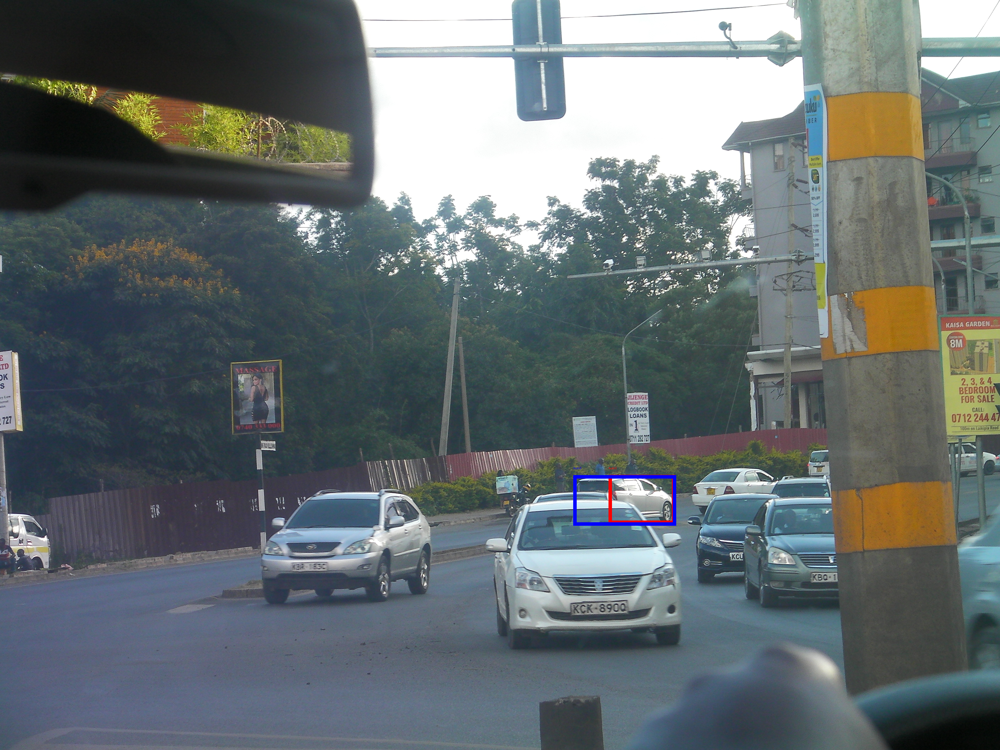


=== VERGROESSERTER BILDBEREICH ===


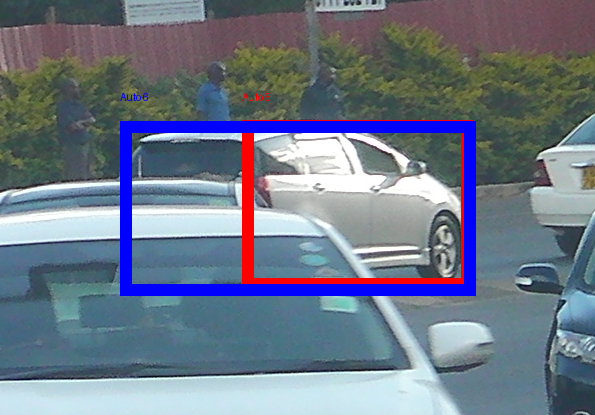

Visualisierung erfolgreich erstellt!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

import json
import os
from PIL import Image, ImageDraw
from IPython.display import display
from google.colab import files

# JSON-Datei laden
json_datei = "ki_fusion_v3.json"

if not os.path.exists(json_datei):
    print("Bitte ki_fusion_v3.json hochladen")
    files.upload()

with open(json_datei, "r", encoding="utf-8") as f:
    daten = json.load(f)

# Originalbild laden
bildname = daten["bild"]

if not os.path.exists(bildname):
    print("Bitte das Originalbild hochladen:", bildname)
    files.upload()

bild = Image.open(bildname).convert("RGB")

# Verdächtiges Paar auslesen
paar = daten["moegliche_doppelerkennungen"][0]

nr1 = paar["erkennung_1"]
nr2 = paar["erkennung_2"]

box1 = daten["yolo_erkennungen"][nr1 - 1]["bbox"]
box2 = daten["yolo_erkennungen"][nr2 - 1]["bbox"]

# Beide Rahmen einzeichnen
markiert = bild.copy()
draw = ImageDraw.Draw(markiert)

draw.rectangle(box1, outline="red", width=12)
draw.rectangle(box2, outline="blue", width=12)

draw.text(
    (box1[0], max(0, box1[1] - 30)),
    f"Auto {nr1}",
    fill="red"
)

draw.text(
    (box2[0], max(0, box2[1] - 30)),
    f"Auto {nr2}",
    fill="blue"
)

# Gesamtes Bild anzeigen
vorschau = markiert.copy()
vorschau.thumbnail((1000, 800))

print("=== DUPLIKAT VISUALISIERUNG ===")
print(f"Erkennung {nr1} (ROT)")
print(f"Erkennung {nr2} (BLAU)")
print("IoU:", paar["iou"])

display(vorschau)

# Verdaechtigen Bildbereich vergroessern
rand = 120

links = max(0, int(min(box1[0], box2[0]) - rand))
oben = max(0, int(min(box1[1], box2[1]) - rand))
rechts = min(bild.width, int(max(box1[2], box2[2]) + rand))
unten = min(bild.height, int(max(box1[3], box2[3]) + rand))

zoom = markiert.crop((links, oben, rechts, unten))
zoom.thumbnail((1000, 800))

print("\n=== VERGROESSERTER BILDBEREICH ===")
display(zoom)

# Markiertes Bild speichern
markiert.save("duplikat_visualisierung.png")

print("Visualisierung erfolgreich erstellt!")
files.download("duplikat_visualisierung.png")


In [10]:

import json
import os
from google.colab import files

# Vorherigen Bericht laden
datei = "ki_fusion_v3.json"

if not os.path.exists(datei):
    print("Bitte ki_fusion_v3.json hochladen")
    files.upload()

with open(datei, "r", encoding="utf-8") as f:
    daten = json.load(f)

# Manuellen Befund dokumentieren
for paar in daten["moegliche_doppelerkennungen"]:
    if (
        paar["erkennung_1"] == 5
        and paar["erkennung_2"] == 6
    ):
        paar["manuell_geprueft"] = True
        paar["ist_doppelerkennung"] = False
        paar["kommentar"] = (
            "Zwei unterschiedliche Fahrzeuge. "
            "Ein Fahrzeug steht hinter dem anderen. "
            "Die Bounding Boxes ueberlappen "
            "aufgrund der Kameraperspektive."
        )

# Neuen Bericht speichern
neue_datei = "ki_fusion_v3_geprueft.json"

with open(neue_datei, "w", encoding="utf-8") as f:
    json.dump(daten, f, indent=4, ensure_ascii=False)

print("=== MANUELLE DUPLIKAT-PRUEFUNG ===")
print("Erkennung 5 und 6")
print("IoU: 0.624")
print("Ergebnis: ZWEI UNTERSCHIEDLICHE AUTOS")
print("Duplikat: NEIN")
print("Bericht erfolgreich aktualisiert!")

files.download(neue_datei)


=== MANUELLE DUPLIKAT-PRUEFUNG ===
Erkennung 5 und 6
IoU: 0.624
Ergebnis: ZWEI UNTERSCHIEDLICHE AUTOS
Duplikat: NEIN
Bericht erfolgreich aktualisiert!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

=== PERSONENERKENNUNG PRÜFEN ===
Erkannte Personen: 1

Person 1
Konfidenz: 0.431


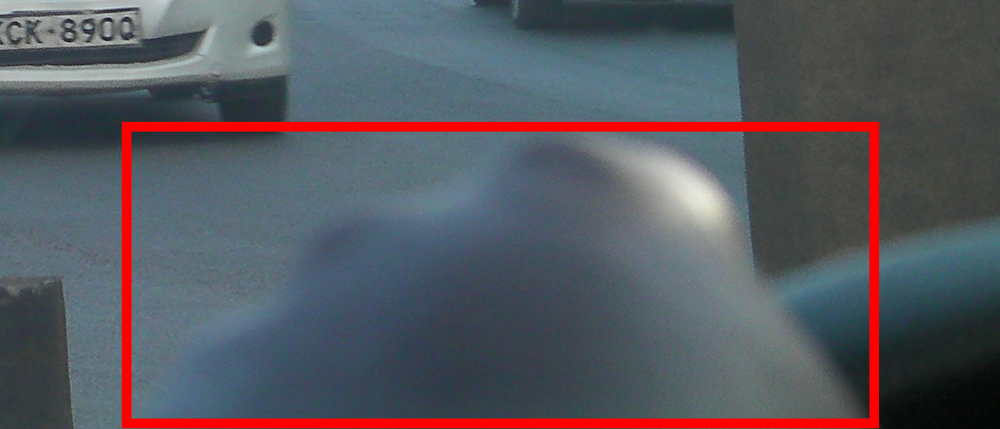


Visuelle Überprüfung abgeschlossen.


In [11]:

import json
import os
from PIL import Image, ImageDraw
from IPython.display import display
from google.colab import files

# Evaluationsbericht laden
datei = "ki_fusion_v3_geprueft.json"

if not os.path.exists(datei):
    datei = "ki_fusion_v3.json"

if not os.path.exists(datei):
    print("Bitte deine JSON-Datei hochladen:")
    hochgeladen = files.upload()
    datei = next(iter(hochgeladen))

with open(datei, "r", encoding="utf-8") as f:
    daten = json.load(f)

# Originalbild laden
bildname = daten["bild"]

if not os.path.exists(bildname):
    print("Bitte das Original-Verkehrsbild hochladen:")
    files.upload()

foto = Image.open(bildname).convert("RGB")

# Personenerkennungen finden
personen = [
    e for e in daten["yolo_erkennungen"]
    if e["objekt"] == "person"
]

print("=== PERSONENERKENNUNG PRÜFEN ===")
print("Erkannte Personen:", len(personen))

for nr, person in enumerate(personen, start=1):
    box = person["bbox"]
    konfidenz = person["konfidenz"]

    # Roten Rahmen zeichnen
    markiert = foto.copy()
    draw = ImageDraw.Draw(markiert)

    draw.rectangle(
        box,
        outline="red",
        width=12
    )

    # Bereich vergrößert anzeigen
    rand = 150

    links = max(0, int(box[0] - rand))
    oben = max(0, int(box[1] - rand))
    rechts = min(foto.width, int(box[2] + rand))
    unten = min(foto.height, int(box[3] + rand))

    ausschnitt = markiert.crop(
        (links, oben, rechts, unten)
    )

    ausschnitt.thumbnail((1000, 800))

    print(f"\nPerson {nr}")
    print(f"Konfidenz: {konfidenz:.3f}")
    display(ausschnitt)

print("\nVisuelle Überprüfung abgeschlossen.")


In [12]:

import json
import os
from google.colab import files

# Aktuellen Bericht laden
datei = "ki_fusion_v3_geprueft.json"

if not os.path.exists(datei):
    datei = "ki_fusion_v3.json"

if not os.path.exists(datei):
    print("Bitte deine letzte JSON-Datei hochladen:")
    hochgeladen = files.upload()
    datei = next(iter(hochgeladen))

with open(datei, "r", encoding="utf-8") as f:
    daten = json.load(f)

# Personenerkennung manuell bewerten
anzahl = 0

for erkennung in daten["yolo_erkennungen"]:

    if erkennung["objekt"] == "person":

        erkennung["manuelle_pruefung"] = {
            "status": "false_positive",
            "tatsaechlicher_inhalt": "unscharfe Hand",
            "kommentar": (
                "YOLO klassifiziert eine unscharfe "
                "Hand im Vordergrund als Person."
            )
        }

        anzahl += 1

# Dokumentation ergänzen
daten["personenerkennung_pruefung"] = {
    "gepruefte_erkennungen": anzahl,
    "false_positives": anzahl,
    "bewertung": "Hand als Person fehlklassifiziert"
}

# Aktualisierte JSON-Datei speichern
ausgabe = "ki_fusion_v4_geprueft.json"

with open(ausgabe, "w", encoding="utf-8") as f:
    json.dump(daten, f, indent=4, ensure_ascii=False)

print("=== PERSONENERKENNUNG EVALUATION ===")
print("Geprüfte Erkennungen:", anzahl)
print("False Positives:", anzahl)
print("Ursache: Unscharfe Hand als Person erkannt")
print("\nEvaluation erfolgreich aktualisiert!")

files.download(ausgabe)


=== PERSONENERKENNUNG EVALUATION ===
Geprüfte Erkennungen: 1
False Positives: 1
Ursache: Unscharfe Hand als Person erkannt

Evaluation erfolgreich aktualisiert!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

import cv2
import json
import subprocess
from ultralytics import YOLO
from google.colab import files
from IPython.display import display, Video

# 1. Verkehrsvideo hochladen
print("Bitte dein MP4-Verkehrsvideo auswählen:")
uploaded = files.upload()

videodatei = next(iter(uploaded))

# 2. YOLO-Modell laden
tracker_modell = YOLO("yolo11n.pt")

# 3. Video öffnen
cap = cv2.VideoCapture(videodatei)

if not cap.isOpened():
    raise RuntimeError("Video konnte nicht geöffnet werden.")

fps = cap.get(cv2.CAP_PROP_FPS)
if fps <= 0:
    fps = 25.0

breite = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
hoehe = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Video verkleinern, um Rechenzeit zu sparen
faktor = min(1.0, 640 / breite)
neue_breite = max(2, int(breite * faktor) // 2 * 2)
neue_hoehe = max(2, int(hoehe * faktor) // 2 * 2)

# 4. Ausgabevideo vorbereiten
ausgabe_raw = "tracking_raw.mp4"

writer = cv2.VideoWriter(
    ausgabe_raw,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (neue_breite, neue_hoehe)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Ausgabevideo konnte nicht erstellt werden.")

# Maximal 150 Frames für den ersten Test
max_frames = min(150, max(1, int(fps * 8)))

frame_nummer = 0
track_ids = {}

# 5. Tracking ausführen
while frame_nummer < max_frames:
    erfolg, frame = cap.read()

    if not erfolg:
        break

    frame = cv2.resize(
        frame, (neue_breite, neue_hoehe)
    )

    resultat_video = tracker_modell.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.25,
        imgsz=480,
        device="cpu",
        verbose=False
    )[0]

    # Objekte mit ID und Rahmen einzeichnen
    markiert = resultat_video.plot()
    writer.write(markiert)

    # Track-IDs erfassen
    boxen = resultat_video.boxes

    if boxen is not None and boxen.is_track:
        for objekt_id, klasse in zip(
            boxen.id.int().tolist(),
            boxen.cls.int().tolist()
        ):
            track_ids[objekt_id] = (
                resultat_video.names[klasse]
            )

    frame_nummer += 1

cap.release()
writer.release()

# 6. Video browserkompatibel konvertieren
ausgabe = "vehicle_tracking.mp4"

subprocess.run(
    [
        "ffmpeg", "-y", "-loglevel", "error",
        "-i", ausgabe_raw,
        "-c:v", "libx264",
        "-pix_fmt", "yuv420p",
        ausgabe
    ],
    check=True
)

# 7. Ergebnis anzeigen
print("=== VIDEO TRACKING ERFOLGREICH ===")
print("Analysierte Frames:", frame_nummer)
print("Vergebene Track-IDs:", len(track_ids))

display(Video(ausgabe, embed=True, width=640))

# 8. Ergebnisvideo herunterladen
files.download(ausgabe)


Bitte dein MP4-Verkehrsvideo auswählen:


Saving vehicle_tracking.mp4 to vehicle_tracking (1).mp4
=== VIDEO TRACKING ERFOLGREICH ===
Analysierte Frames: 150
Vergebene Track-IDs: 8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

import torch
from transformers import (
    AutoProcessor,
    AutoModelForImageTextToText
)

model_name = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"

print("SmolVLM2 wird vorbereitet ...")

# Bildverarbeitung laden
if "processor" not in globals():
    processor = AutoProcessor.from_pretrained(
        model_name
    )

# KI-Modell laden
if "model" not in globals():
    model = AutoModelForImageTextToText.from_pretrained(
        model_name,
        dtype=torch.float16,
        device_map="auto"
    )

model.eval()

print("\n=== SMOLVLM2 BEREIT ===")
print("Processor: OK")
print("KI-Modell: OK")
print("Gerät:", model.device)


SmolVLM2 wird vorbereitet ...


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]


=== SMOLVLM2 BEREIT ===
Processor: OK
KI-Modell: OK
Gerät: cuda:0



=== SZENE 1 ===


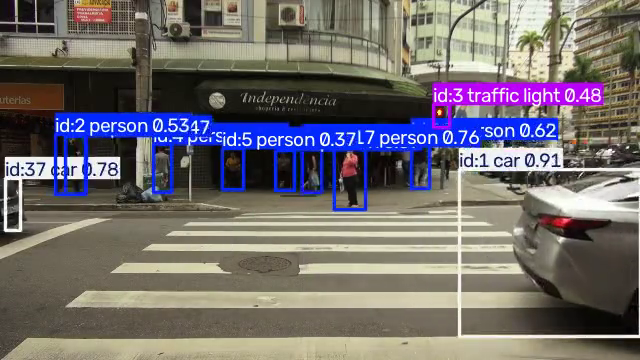

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


Zeitpunkt: 0.37 Sekunden
KI-Beschreibung: A silver car is driving on the road, a person is walking on the sidewalk, a traffic light is present, and there are two traffic lights in the scene.

=== SZENE 2 ===


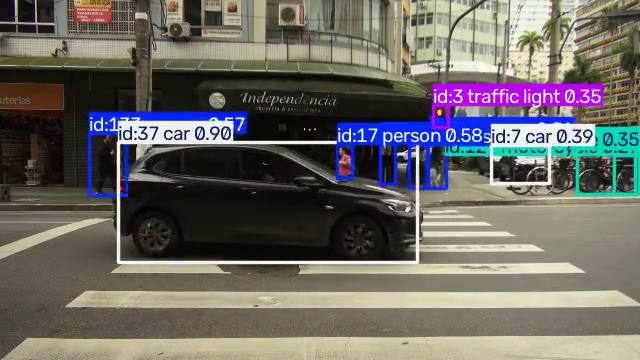

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


Zeitpunkt: 1.23 Sekunden
KI-Beschreibung: A black car is on the road, a person is walking, a traffic light is present, and there are bicycles parked.

=== SZENE 3 ===


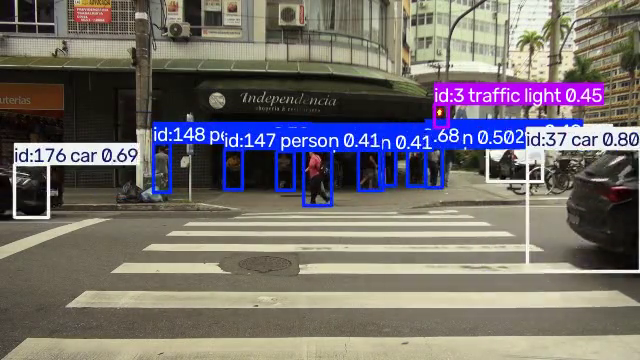

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


Zeitpunkt: 2.1 Sekunden
KI-Beschreibung: A black car is driving on the road, a pedestrian is crossing the street, a traffic light is present, and there are buildings in the background.

=== VIDEOANALYSE ABGESCHLOSSEN ===
Analysierte Szenen: 3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:

import cv2
import os
import json
import torch
from PIL import Image
from google.colab import files
from IPython.display import display

# Originalvideo verwenden, möglichst ohne YOLO-Rahmen
if "videodatei" in globals() and os.path.exists(videodatei):
    video_pfad = videodatei
else:
    print("Bitte das ORIGINAL-MP4-Video hochladen:")
    uploaded = files.upload()
    video_pfad = next(iter(uploaded))

# SmolVLM2 muss geladen sein
if "model" not in globals() or "processor" not in globals():
    raise RuntimeError(
        "Bitte zuerst deine Codezelle zum Laden "
        "von SmolVLM2 ausführen."
    )

cap = cv2.VideoCapture(video_pfad)

if not cap.isOpened():
    raise RuntimeError("Video konnte nicht geöffnet werden.")

gesamt_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)

if gesamt_frames <= 0:
    cap.release()
    raise RuntimeError("Keine Videoframes gefunden.")

if fps <= 0:
    fps = 25

# Drei Zeitpunkte auswählen
positionen = [
    int((gesamt_frames - 1) * anteil)
    for anteil in [0.15, 0.50, 0.85]
]

video_ergebnisse = []

for nummer, position in enumerate(positionen, start=1):

    cap.set(cv2.CAP_PROP_POS_FRAMES, position)
    ok, frame = cap.read()

    if not ok:
        continue

    bild_rgb = cv2.cvtColor(
        frame, cv2.COLOR_BGR2RGB
    )

    frame_bild = Image.fromarray(bild_rgb)
    frame_bild.thumbnail((768, 768))

    print(f"\n=== SZENE {nummer} ===")
    display(frame_bild)

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": frame_bild},
                {
                    "type": "text",
                    "text": (
                        "Describe this traffic scene. "
                        "Mention vehicles, pedestrians, "
                        "traffic lights and road conditions. "
                        "Use 2 short sentences. "
                        "Only describe visible objects."
                    )
                }
            ]
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(model.device, dtype=torch.float16)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False
        )

    input_length = inputs["input_ids"].shape[-1]

    beschreibung = processor.decode(
        outputs[0][input_length:],
        skip_special_tokens=True
    ).strip()

    zeitpunkt = round(position / fps, 2)

    print("Zeitpunkt:", zeitpunkt, "Sekunden")
    print("KI-Beschreibung:", beschreibung)

    video_ergebnisse.append({
        "szene": nummer,
        "zeitpunkt_sekunden": zeitpunkt,
        "beschreibung": beschreibung
    })

cap.release()

# JSON-Bericht erstellen
bericht = {
    "projekt": "GenAI Vehicle Scene Analyzer 3.0",
    "video": video_pfad,
    "modell": "SmolVLM2-2.2B-Instruct",
    "szenen": video_ergebnisse
}

with open("video_ki_analyse.json", "w", encoding="utf-8") as f:
    json.dump(bericht, f, indent=4, ensure_ascii=False)

print("\n=== VIDEOANALYSE ABGESCHLOSSEN ===")
print("Analysierte Szenen:", len(video_ergebnisse))

files.download("video_ki_analyse.json")


In [5]:

import cv2
import json
import subprocess
import numpy as np
from collections import defaultdict, deque, Counter
from ultralytics import YOLO
from google.colab import files
from IPython.display import Video, display

# 1. Originalvideo hochladen
print("Bitte das ORIGINALVIDEO ohne Markierungen hochladen")
uploaded = files.upload()
videodatei = next(iter(uploaded))

# 2. Neues YOLO-Modell mit frischem Tracker
tracker = YOLO("yolo11n.pt")

cap = cv2.VideoCapture(videodatei)

if not cap.isOpened():
    raise RuntimeError("Video konnte nicht geöffnet werden")

fps = cap.get(cv2.CAP_PROP_FPS) or 25
breite = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
hoehe = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

if breite <= 0 or hoehe <= 0:
    cap.release()
    raise RuntimeError("Ungültige Videogröße")

# Auflösung begrenzen
faktor = min(1.0, 640 / breite)
w = max(2, int(breite * faktor) // 2 * 2)
h = max(2, int(hoehe * faktor) // 2 * 2)

writer = cv2.VideoWriter(
    "bewegung_raw.mp4",
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (w, h)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Videodatei nicht schreibbar")

# 3. Positionsverläufe speichern
verlaeufe = defaultdict(lambda: deque(maxlen=12))
beobachtungen = Counter()
objektklassen = {}
richtungen = {}

bewegliche_klassen = {
    "car", "truck", "bus",
    "motorcycle", "bicycle", "person"
}

def bestimme_richtung(dx, dy):
    # Richtung in Bildkoordinaten
    horizontal = (
        "rechts" if dx > 12 else
        "links" if dx < -12 else ""
    )

    vertikal = (
        "unten" if dy > 12 else
        "oben" if dy < -12 else ""
    )

    return "-".join(
        x for x in [horizontal, vertikal] if x
    ) or "kaum Bewegung"

frame_nummer = 0

# 4. Maximal 150 Frames analysieren
while frame_nummer < 150:

    ok, frame = cap.read()
    if not ok:
        break

    frame = cv2.resize(frame, (w, h))

    result = tracker.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.25,
        imgsz=480,
        device="cpu",
        verbose=False
    )[0]

    markiert = result.plot()
    boxen = result.boxes

    if boxen is not None and boxen.id is not None:

        ids = boxen.id.int().cpu().tolist()
        klassen = boxen.cls.int().cpu().tolist()
        positionen = boxen.xywh.cpu().tolist()

        for track_id, klasse, box in zip(
            ids, klassen, positionen
        ):

            name = result.names[klasse]

            if name not in bewegliche_klassen:
                continue

            x, y = int(box[0]), int(box[1])

            verlauf = verlaeufe[track_id]
            verlauf.append((x, y))

            beobachtungen[track_id] += 1
            objektklassen[track_id] = name

            if len(verlauf) >= 4:
                alt_x, alt_y = verlauf[0]

                dx = x - alt_x
                dy = y - alt_y

                richtung = bestimme_richtung(dx, dy)
                richtungen[track_id] = richtung

                if richtung != "kaum Bewegung":

                    cv2.arrowedLine(
                        markiert,
                        (alt_x, alt_y),
                        (x, y),
                        (0, 255, 255),
                        3,
                        tipLength=0.25
                    )

                    cv2.putText(
                        markiert,
                        f"ID {track_id}: {richtung}",
                        (max(0, x - 55), max(20, y - 20)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.45,
                        (0, 255, 255),
                        2
                    )

    writer.write(markiert)
    frame_nummer += 1

cap.release()
writer.release()

# 5. Video für Colab konvertieren
subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error",
    "-i", "bewegung_raw.mp4",
    "-c:v", "libx264",
    "-pix_fmt", "yuv420p",
    "bewegungsanalyse.mp4"
], check=True)

# 6. JSON-Ergebnisse speichern
tracks = []

for track_id in sorted(objektklassen):
    tracks.append({
        "track_id": track_id,
        "objekt": objektklassen[track_id],
        "beobachtete_frames": beobachtungen[track_id],
        "letzte_richtung_im_bild": richtungen.get(
            track_id, "nicht bestimmt"
        )
    })

bericht = {
    "projekt": "GenAI Vehicle Scene Analyzer 3.1",
    "analysierte_frames": frame_nummer,
    "bewegungen": tracks,
    "hinweis": (
        "Richtungen beziehen sich nur auf das Bild. "
        "Track-IDs sind keine garantierten Objektidentitäten."
    )
}

with open("bewegungsanalyse.json", "w") as f:
    json.dump(bericht, f, indent=4)

print("=== BEWEGUNGSANALYSE ABGESCHLOSSEN ===")
print("Analysierte Frames:", frame_nummer)
print("Track-IDs:", len(tracks))

display(Video("bewegungsanalyse.mp4", embed=True, width=640))

files.download("bewegungsanalyse.mp4")
files.download("bewegungsanalyse.json")


Bitte das ORIGINALVIDEO ohne Markierungen hochladen


Saving 12710935_1920_1080_60fps.mp4 to 12710935_1920_1080_60fps (1).mp4
=== BEWEGUNGSANALYSE ABGESCHLOSSEN ===
Analysierte Frames: 150
Track-IDs: 39


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>